# 4. Anomaly detection

Goal: flag unusual days in the Paris PM2.5 daily series with **three independent methods**, check where they agree, and decide which points to clean before re-forecasting (notebook 05).

| Method | Type | Input |
|---|---|---|
| Rolling Z-score on STL residuals | statistical | robust STL (period 7) residuals, 30-day centered window, \|z\| > 3 |
| SARIMA residuals beyond 3 sigma | statistical | ARIMA(2,0,2) fitted on the **training** set (Yahya's AIC choice), applied to the full series |
| Isolation Forest | machine learning | value, lag 1, lag 7, first difference, rolling 7-day mean/std, deviation from the 30-day median |

An observation is called **agreed** when at least two methods flag it. Only agreed anomalies are cleaned.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root))
os.chdir(project_root)

from src.anomalies import (
    combine_flags,
    isolation_forest_anomalies,
    overlap_table,
    sarima_residual_anomalies,
    stl_residual_anomalies,
)
from src.eda import impute_linear
from src.load_data import get_train_test, load_daily_series
from src.plots import save_current_figure

DATA_PATH = project_root / "data/processed/pm25_paris_daily.csv"
(project_root / "reports/tables").mkdir(parents=True, exist_ok=True)

series = impute_linear(load_daily_series(DATA_PATH))
train, test = get_train_test(series)
print(f"{len(series)} days, train {len(train)}, test {len(test)}")

1034 days, train 944, test 90


## Rolling Z-score on STL residuals

The robust STL removes trend and the (weak) weekly pattern. A centered 30-day rolling mean/std of the residual makes the threshold adapt to the season, since winter is much more volatile than summer.

STL Z-score anomalies: 16


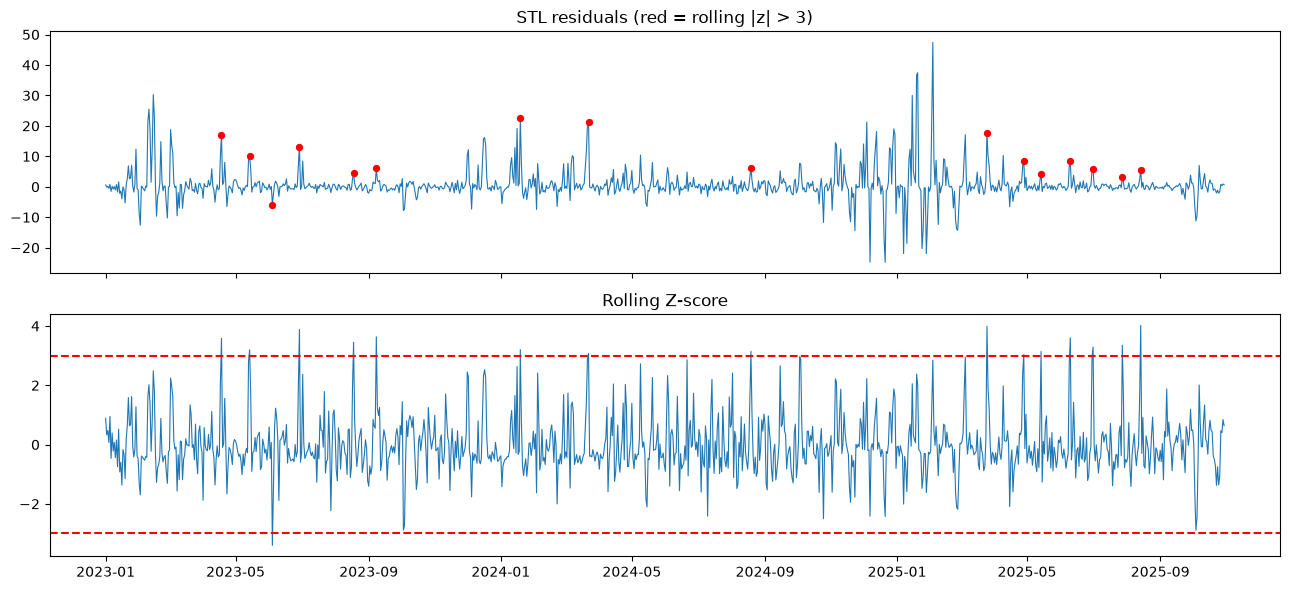

In [2]:
stl_flags, stl_fit = stl_residual_anomalies(series, period=7, window=30, threshold=3.0)
print("STL Z-score anomalies:", int(stl_flags["is_anomaly"].sum()))

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
axes[0].plot(stl_fit.resid.index, stl_fit.resid.values, linewidth=0.8)
hit = stl_flags.index[stl_flags["is_anomaly"]]
axes[0].scatter(hit, stl_fit.resid[hit], color="red", s=18, zorder=3)
axes[0].set_title("STL residuals (red = rolling |z| > 3)")
axes[1].plot(stl_flags.index, stl_flags["zscore"], linewidth=0.8)
axes[1].axhline(3, color="red", linestyle="--"); axes[1].axhline(-3, color="red", linestyle="--")
axes[1].set_title("Rolling Z-score")
fig.tight_layout()
save_current_figure("04_stl_zscore.png")
plt.show()

## SARIMA residual anomalies

ARIMA(2,0,2) is fitted on the training set only, then applied to the whole series to get one-step-ahead residuals. A point is flagged when its residual is more than three training-residual standard deviations from zero. Because the residuals are heavy-tailed and larger in winter (see notebook 03) this method is expected to flag more points than a Gaussian would.

SARIMA residual anomalies: 22


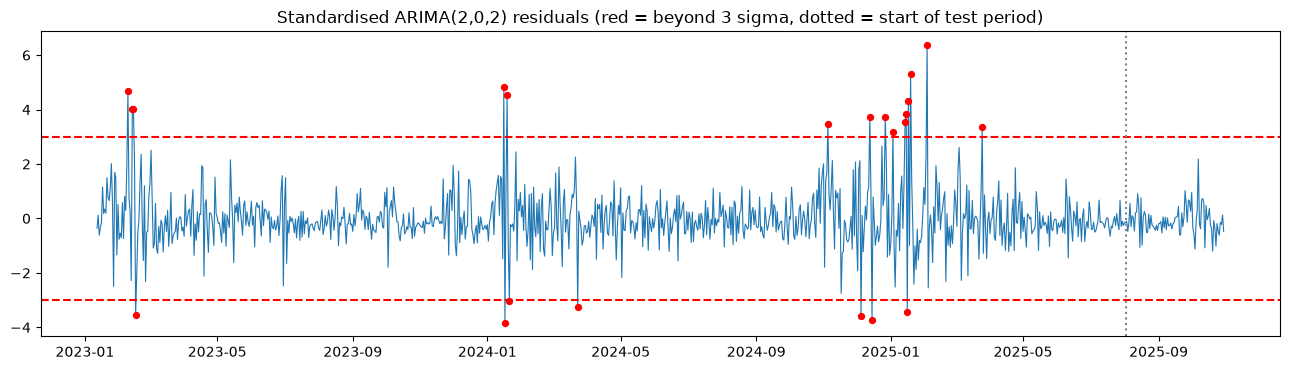

In [3]:
sarima_flags = sarima_residual_anomalies(train, series, order=(2, 0, 2), threshold=3.0)
print("SARIMA residual anomalies:", int(sarima_flags["is_anomaly"].sum()))

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(sarima_flags.index, sarima_flags["zscore"], linewidth=0.8)
ax.axhline(3, color="red", linestyle="--"); ax.axhline(-3, color="red", linestyle="--")
hit = sarima_flags.index[sarima_flags["is_anomaly"]]
ax.scatter(hit, sarima_flags.loc[hit, "zscore"], color="red", s=18, zorder=3)
ax.axvline(test.index[0], color="gray", linestyle=":")
ax.set_title("Standardised ARIMA(2,0,2) residuals (red = beyond 3 sigma, dotted = start of test period)")
fig.tight_layout()
save_current_figure("04_sarima_residuals.png")
plt.show()

## Machine learning method: Isolation Forest

Features mix the level, short memory (lag 1, lag 7, first difference) and local context (rolling mean/std, deviation from the 30-day median). `contamination = 3%` is an assumption about the anomaly rate, not an estimate.

In [4]:
iforest = isolation_forest_anomalies(series, contamination=0.03, random_state=42)
print("Isolation Forest anomalies:", int(iforest["is_anomaly"].sum()))

Isolation Forest anomalies: 31


## Anomalies on the series and method overlap

Number of methods flagging each day:
n_methods
0    981
1     38
2     14
3      1


,STL Z-score,SARIMA 3-sigma,Isolation Forest
STL Z-score,16,2,1
SARIMA 3-sigma,2,22,14
Isolation Forest,1,14,31


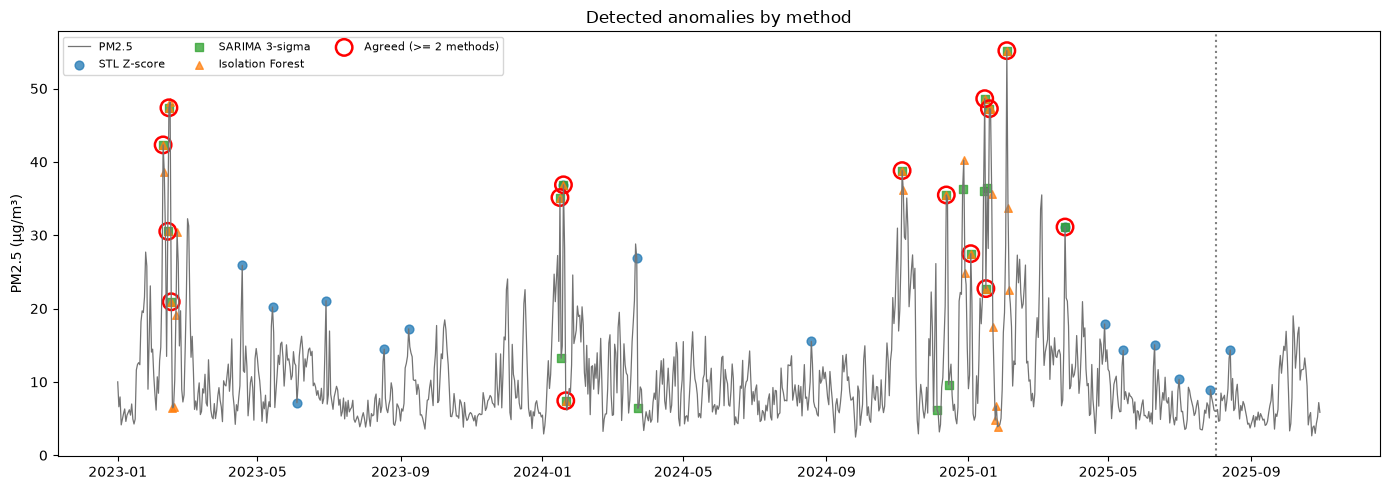

In [5]:
flags = combine_flags(
    {
        "STL Z-score": stl_flags["is_anomaly"],
        "SARIMA 3-sigma": sarima_flags["is_anomaly"],
        "Isolation Forest": iforest["is_anomaly"],
    },
    series.index,
)
agreed = flags["n_methods"] >= 2

print("Number of methods flagging each day:")
print(flags["n_methods"].value_counts().sort_index().to_string())

overlap = overlap_table(flags)
display(overlap)
overlap.to_csv("reports/tables/04_anomaly_overlap.csv")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(series.index, series.values, color="0.45", linewidth=0.9, label="PM2.5")
styles = {
    "STL Z-score": ("tab:blue", "o", 40),
    "SARIMA 3-sigma": ("tab:green", "s", 30),
    "Isolation Forest": ("tab:orange", "^", 30),
}
for name, (color, marker, size) in styles.items():
    pts = series[flags[name]]
    ax.scatter(pts.index, pts.values, color=color, marker=marker, s=size, alpha=0.75, label=name)
ax.scatter(series[agreed].index, series[agreed].values, facecolors="none", edgecolors="red",
           s=140, linewidths=1.8, label="Agreed (>= 2 methods)")
ax.axvline(test.index[0], color="gray", linestyle=":")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Detected anomalies by method")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()
save_current_figure("04_anomalies_overview.png")
plt.show()

In [6]:
agreed_table = pd.DataFrame(
    {
        "pm25": series[agreed].round(1),
        "n_methods": flags.loc[agreed, "n_methods"],
        "methods": flags.loc[agreed].drop(columns="n_methods").apply(lambda r: ", ".join(r.index[r]), axis=1),
        "month": series[agreed].index.strftime("%Y-%m"),
        "weekday": series[agreed].index.day_name(),
        "in_test": series[agreed].index.isin(test.index),
    }
)
display(agreed_table)
agreed_table.to_csv("reports/tables/04_agreed_anomalies.csv")
flags.to_csv("reports/tables/04_anomaly_flags.csv")
print(f"Agreed anomalies: {int(agreed.sum())} ({agreed.mean():.1%} of days), of which in the test period: {int(agreed[test.index].sum())}")

,pm25,n_methods,methods,month,weekday,in_test
date,,,,,,
2023-02-09,42.3,2,"SARIMA 3-sigma, Isolation Forest",2023-02,Thursday,False
2023-02-13,30.5,2,"SARIMA 3-sigma, Isolation Forest",2023-02,Monday,False
2023-02-14,47.4,2,"SARIMA 3-sigma, Isolation Forest",2023-02,Tuesday,False
2023-02-16,20.9,2,"SARIMA 3-sigma, Isolation Forest",2023-02,Thursday,False
2024-01-16,35.1,2,"SARIMA 3-sigma, Isolation Forest",2024-01,Tuesday,False
2024-01-19,36.9,3,"STL Z-score, SARIMA 3-sigma, Isolation Forest",2024-01,Friday,False
2024-01-21,7.4,2,"SARIMA 3-sigma, Isolation Forest",2024-01,Sunday,False
2024-11-05,38.8,2,"SARIMA 3-sigma, Isolation Forest",2024-11,Tuesday,False
2024-12-13,35.5,2,"SARIMA 3-sigma, Isolation Forest",2024-12,Friday,False


Agreed anomalies: 15 (1.5% of days), of which in the test period: 0


## Real-world causes

Matching the agreed dates to known context. These are **plausible explanations, not verified attributions**: we did not have weather or traffic data, so each cause should be read as a hypothesis.

In [7]:
summary = agreed_table.assign(
    season=lambda d: pd.to_datetime(d.index).month.map(
        lambda m: "winter (Dec-Feb)" if m in (12, 1, 2) else "spring (Mar-May)" if m in (3, 4, 5)
        else "summer (Jun-Aug)" if m in (6, 7, 8) else "autumn (Sep-Nov)"
    )
)
display(summary["season"].value_counts().to_frame("agreed anomalies"))
display(summary.groupby(summary.index.year).size().to_frame("agreed anomalies").rename_axis("year"))
low = (agreed_table["pm25"] < series.median()).sum()
print(f"Agreed anomalies below the series median (possible sensor dips): {low}")

,agreed anomalies
season,
winter (Dec-Feb),13
autumn (Sep-Nov),1
spring (Mar-May),1


,agreed anomalies
year,
2023,4
2024,5
2025,6


Agreed anomalies below the series median (possible sensor dips): 1


**Reading of the results** (hypotheses to verify against Airparif bulletins and weather data)

- Most agreed anomalies are **high PM2.5 days in winter** (February 2023, January 2024, November to December 2024, January to February 2025). This is the signature of regional **pollution episodes**: cold, still anticyclonic weather traps particles, and residential wood heating and traffic emissions add to them.
- **25 March 2025** (31 µg/m³) falls in a spring period; spring episodes in northern France are typically driven by ammonium-nitrate formation from agricultural emissions, sometimes combined with imported dust. We did not verify this date against an official bulletin.
- Isolated **low outliers** (for example 21 January 2024 at 7.4 µg/m³ two days after a 37 µg/m³ day) are more consistent with a **sharp weather change** (wind or rain washing out particles) or a **sensor/reporting artefact** than with a real emission change.
- No agreed anomaly falls in the 90-day test window (Aug to Oct 2025, a low-pollution season), so cleaning cannot change the test targets.
- Fireworks (14 July, 31 December) did not appear among the agreed points: with daily means the short evening peak is diluted.